# 03 Bayesian inference: the scan is clear. Is she safe?

*Teaching material. Not for clinical use.*

A casualty reaches pre-hospital emergency care. The medic scans her abdomen for free fluid and sees none.

Suppose that, before the scan, one casualty in five like her is bleeding into the abdomen. That share is an assumption made for this example; later the generator supplies its own.

**Before reading on, guess.** After the clear scan, how likely is it that she is bleeding into the abdomen?

- Under 1%: a clear scan rules it out
- About 5%
- About 16%
- Still about 20%: the scan told us nothing

Write the guess down. It is not marked, and the answer comes in the diagnosis case below.

In [1]:
%matplotlib inline
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import generator
from inference_labs.belief import RV
from inference_labs.lenses import bayesian as bayes

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID = "#7f2704", "#d9d9d9", "#08306b"   # bleeding, not bleeding, before hospital
PALE = "#6baed6"                                      # in hospital: lighter, and drawn dashed or hatched
pd.set_option("display.precision", 3)

## The idea, before any medicine

Suppose a kitchen has a smoke alarm that is good at one thing and poor at another. It almost never sounds for burnt toast. But it misses most slow, smouldering fires, which creep past it without enough smoke.

If the alarm sounds, you should take it seriously: toast rarely sets it off. If the alarm is silent, you should not relax much: it is silent for most fires. How far either result should move you also depends on how often there is a fire in that kitchen in the first place.

That is the whole of Bayesian inference. The rest of this notebook adds counting, uncertainty and a casualty.

**Plain.** What you believe after a test depends on what you believed before it. A good test moves a belief; it does not replace one. A test that misses most of what it looks for can say "yes" with force but can say "no" only weakly. Saying where you began is a strength, not an embarrassment: it is the part of the answer someone else can check and argue with.

**Developer.** A belief is a probability, carried through the pathway as an `RV` (E-70): an array of 4,000 draws with arithmetic defined on it. One update is a function `update(belief, sensitivity, specificity, positive)` that returns a new `RV`. Sensitivity and specificity are `RV`s too, so the uncertainty in the test flows into the belief. Each step costs a handful of array operations. Summaries (`mean`, `interval`, `prob`) are taken only at the end.

```python
def update(belief, sens, spec, positive):
    if positive:
        return belief * sens / (belief * sens + (1 - belief) * (1 - spec))
    return belief * (1 - sens) / (belief * (1 - sens) + (1 - belief) * spec)
```

**Technical.** For a condition $D$ and a finding $T$, Bayes' theorem in odds form is

$$\frac{P(D \mid T)}{P(\bar D \mid T)} = \frac{P(D)}{P(\bar D)} \times \mathrm{LR}, \qquad \mathrm{LR}^{+} = \frac{\mathrm{sens}}{1 - \mathrm{spec}}, \quad \mathrm{LR}^{-} = \frac{1 - \mathrm{sens}}{\mathrm{spec}}.$$

Sensitivity and specificity are unknown proportions. With $a$ true positives and $c$ false negatives, sensitivity is given the distribution $\mathrm{Beta}(a, c)$; specificity likewise from the true negatives and false positives. The posterior belief is then a function of two random variables and is itself a random variable, represented by $S$ paired draws. Updating on several findings in turn assumes each is independent of the earlier ones given $D$; where that fails, the product of likelihood ratios overstates certainty.

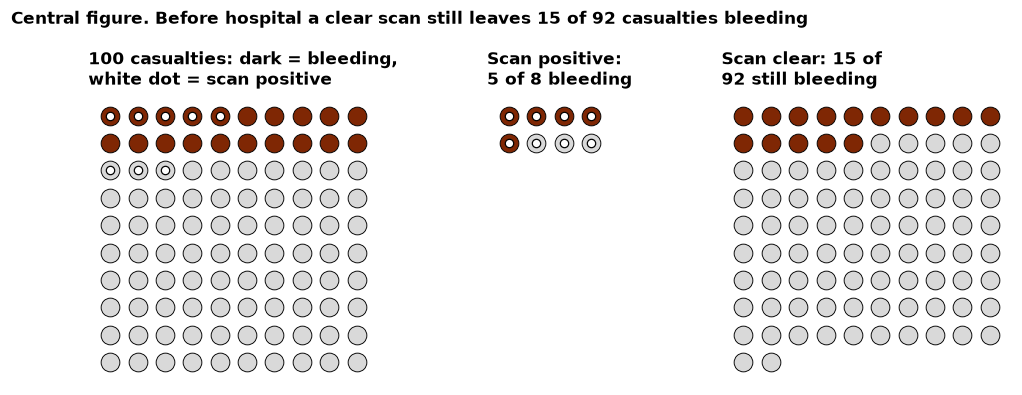

In [2]:
# Central figure: a hundred casualties, twenty of them bleeding (the assumed one in five), scanned before hospital.
# Expected counts from E-16: the scan finds 21 of 84 cases of free fluid and clears 257 of 266 without it.
sens_pre, spec_pre = 21 / 84, 257 / 266
bleeding, not_bleeding = 20, 80
found = round(bleeding * sens_pre)                 # bleeding, scan positive
false_alarm = round(not_bleeding * (1 - spec_pre))  # not bleeding, scan positive

def person_grid(ax, groups, cols=10, title=""):
    # groups: list of (count, colour, marked) drawn in order, row by row
    k = 0
    for count, colour, marked in groups:
        for _ in range(count):
            x, y = k % cols, -(k // cols)
            ax.scatter(x, y, s=150, color=colour, edgecolor="black", linewidth=0.6, zorder=2)
            if marked:
                ax.scatter(x, y, s=30, color="white", edgecolor="black", linewidth=0.8, zorder=3)
            k += 1
    ax.set_xlim(-0.8, cols - 0.2)
    ax.set_ylim(-9.8, 0.8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, loc="left")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={"width_ratios": [10, 4, 10]})
person_grid(axes[0], [(found, DARK, True), (bleeding - found, DARK, False),
                      (false_alarm, LIGHT, True), (not_bleeding - false_alarm, LIGHT, False)],
            title="100 casualties: dark = bleeding,\nwhite dot = scan positive")
person_grid(axes[1], [(found, DARK, True), (false_alarm, LIGHT, True)], cols=4,
            title=f"Scan positive:\n{found} of {found + false_alarm} bleeding")
person_grid(axes[2], [(bleeding - found, DARK, False), (not_bleeding - false_alarm, LIGHT, False)],
            title=f"Scan clear: {bleeding - found} of\n{100 - found - false_alarm} still bleeding")
fig.suptitle(f"Central figure. Before hospital a clear scan still leaves {bleeding - found} of "
             f"{100 - found - false_alarm} casualties bleeding", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

The grid is the answer, counted. People reason about a test better when it is given as counts of people rather than as percentages (E-64, E-114), and a picture of the counts helps further: in 108 patients given counts, adding a grid raised accuracy from 32% to 55% (E-64). Both findings are from statistically naive participants or patients, not clinicians.

## By hand: the same hundred, in hospital and before it

The same scan behaves very differently by setting. In hospital, pooled studies give 74% sensitivity and 98% specificity for free fluid (E-14). Before hospital, one civilian helicopter service found 21 of 84 cases of free fluid and correctly cleared 257 of 266 without it: 25% and 96% (E-16). That service treated mostly blunt trauma, and a third of its abdominal scans were recorded as indeterminate. The pre-hospital study is civilian. Using these figures for a military casualty is an assumption.

First by hand, with no library: count what happens to the twenty bleeding and the eighty not bleeding.

In [3]:
settings = {"before hospital": (21 / 84, 257 / 266), "in hospital": (0.74, 0.98)}
rows = []
for name, (sens, spec) in settings.items():
    found = bleeding * sens
    missed = bleeding - found
    false_alarm = not_bleeding * (1 - spec)
    cleared = not_bleeding - false_alarm
    rows.append({"setting": name, "found": found, "missed": missed, "false alarms": false_alarm, "cleared": cleared,
                 "belief if positive": found / (found + false_alarm), "belief if clear": missed / (missed + cleared)})
by_hand = pd.DataFrame(rows).set_index("setting")
by_hand.round(2)

,found,missed,false alarms,cleared,belief if positive,belief if clear
setting,,,,,,
before hospital,5.0,15.0,2.71,77.29,0.65,0.16
in hospital,14.8,5.2,1.60,78.40,0.90,0.06


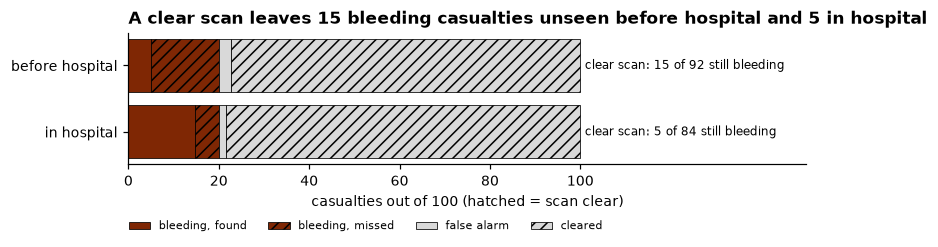

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
for i, (name, row) in enumerate(by_hand.iterrows()):
    y = 1 - i
    left = 0
    for count, colour, hatch, label in ((row["found"], DARK, "", "bleeding, found"), (row["missed"], DARK, "///", "bleeding, missed"),
                                        (row["false alarms"], LIGHT, "", "false alarm"), (row["cleared"], LIGHT, "///", "cleared")):
        ax.barh(y, count, left=left, color=colour, hatch=hatch, edgecolor="black", linewidth=0.5,
                label=label if i == 0 else None)
        left += count
    ax.text(101, y, f"clear scan: {row['missed']:.0f} of {row['missed'] + row['cleared']:.0f} still bleeding",
            va="center", fontsize=8)
ax.set_yticks([1, 0], by_hand.index)
ax.set_xlim(0, 150)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("casualties out of 100 (hatched = scan clear)")
ax.legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(0.35, -0.35), frameon=False)
ax.set_title(f"A clear scan leaves {by_hand.loc['before hospital', 'missed']:.0f} bleeding casualties unseen before hospital "
             f"and {by_hand.loc['in hospital', 'missed']:.0f} in hospital", loc="left")
plt.tight_layout()
plt.show()

### Ten plausible scans, by hand

The 25% is not known exactly. Twenty-one detections out of eighty-four is consistent with a range of true sensitivities, and the same goes for specificity. So draw ten plausible pairs, Beta(21, 63) for sensitivity and Beta(257, 9) for specificity, and work out the belief after a **positive** scan for each, starting from one in five. This is a loop over ten rows, written out.

In [5]:
rng = np.random.default_rng(42)
sens_draws = rng.beta(21, 63, 4000)      # 21 of 84 cases of free fluid detected (E-16)
spec_draws = rng.beta(257, 9, 4000)      # 257 of 266 without free fluid correctly cleared (E-16)
prior = 0.20                             # assumption, as in the hook

ten = []
for s in range(10):
    sens, spec = sens_draws[s], spec_draws[s]
    belief = prior * sens / (prior * sens + (1 - prior) * (1 - spec))
    ten.append({"draw": s + 1, "sensitivity": round(sens, 2), "specificity": round(spec, 2), "belief if positive": round(belief, 2)})
ten = pd.DataFrame(ten).set_index("draw")
ten

,sensitivity,specificity,belief if positive
draw,,,
1,0.24,0.97,0.65
2,0.17,0.96,0.53
3,0.23,0.96,0.59
4,0.24,0.98,0.75
5,0.24,0.97,0.65
6,0.21,0.98,0.72
7,0.22,0.94,0.48
8,0.22,0.95,0.54
9,0.21,0.97,0.63


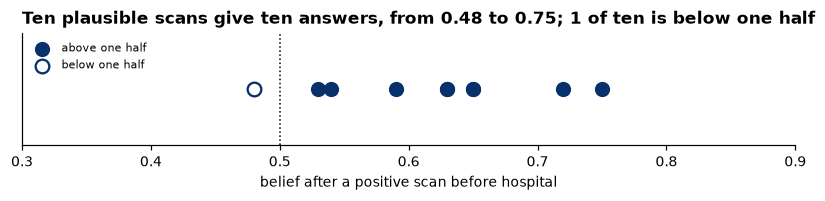

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 1.9))
values = ten["belief if positive"]
below = values < 0.5
ax.scatter(values[~below], np.zeros((~below).sum()), s=80, color=MID, zorder=3, label="above one half")
ax.scatter(values[below], np.zeros(below.sum()), s=80, color="white", edgecolor=MID, linewidth=1.5, zorder=3, label="below one half")
ax.axvline(0.5, color="black", linestyle=":", linewidth=1)
ax.set_xlim(0.3, 0.9)
ax.set_yticks([])
ax.set_xlabel("belief after a positive scan before hospital")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title(f"Ten plausible scans give ten answers, from {values.min():.2f} to {values.max():.2f}; "
             f"{below.sum()} of ten is below one half", loc="left")
plt.tight_layout()
plt.show()

That table is the random variable. Everything after this is the same table with 4,000 rows and the loop hidden. Here it is with the library; the arithmetic on the last line is the formula as it would be written on paper.

In [7]:
sens = RV(sens_draws)
spec = RV(spec_draws)
belief = prior * sens / (prior * sens + (1 - prior) * (1 - spec))

library = bayes.belief_after_scan(0.20, "pre_hospital")       # the same calculation inside the lens
assert np.array_equal(belief.draws, library.draws)
lo, hi = belief.interval()
print(f"best single figure       {belief.mean():.0%}")
print(f"plausible range (95%)    {lo:.0%} to {hi:.0%}")
print(f"chance above one half    {belief.prob(lambda d: d > 0.5):.0%}")

best single figure       65%
plausible range (95%)    48% to 82%
chance above one half    96%


## Diagnosis: the belief after a scan, in both settings

With a positive scan before hospital the belief moves from 20% to about 65%, with a plausible range of 48% to 82%. The point estimate sits comfortably above one half, yet about one time in 25 the belief is really below it, because the scan's accuracy is itself known only roughly.

In hospital the source is a pooled analysis, so the draws there are an assumption: Beta(74, 26) for sensitivity and Beta(294, 6) for specificity, centred on E-14's 74% and 98%. With those, a positive scan gives about 90%, and the whole range is above the line.

In [8]:
results = {}
for setting in bayes.SETTINGS:
    for positive in (True, False):
        rv = bayes.belief_after_scan(0.20, setting, positive)
        lo, hi = rv.interval()
        results[(bayes.SETTING_NAMES[setting], "positive" if positive else "clear")] = rv
        print(f"{bayes.SETTING_NAMES[setting]:16s} {'positive' if positive else 'clear':9s} "
              f"{rv.mean():5.0%}  ({lo:.0%} to {hi:.0%})   above one half: {rv.prob(lambda d: d > 0.5):.0%}")

before hospital  positive    65%  (48% to 82%)   above one half: 96%
before hospital  clear       16%  (14% to 18%)   above one half: 0%
in hospital      positive    90%  (82% to 96%)   above one half: 100%
in hospital      clear        6%  (4% to 8%)   above one half: 0%


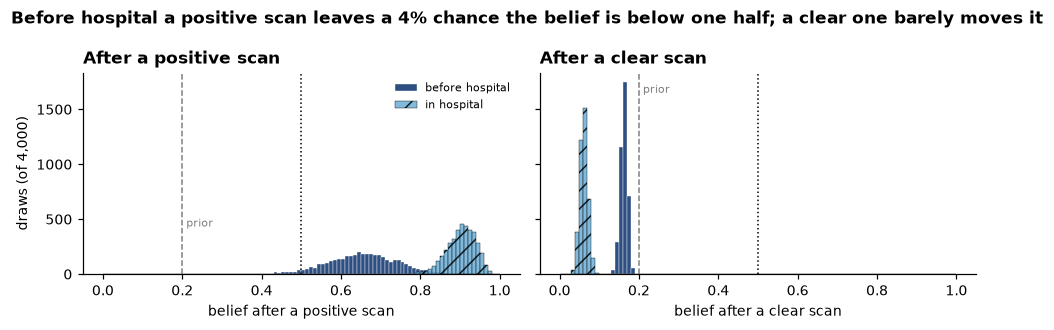

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
bins = np.linspace(0, 1, 101)
for ax, result in zip(axes, ("positive", "clear")):
    for setting, colour, hatch in (("before hospital", MID, None), ("in hospital", PALE, "//")):
        d = results[(setting, result)].draws
        ax.hist(d, bins=bins, color=colour, alpha=0.85, hatch=hatch, edgecolor="white" if hatch is None else "black",
                linewidth=0.3, label=setting)
    ax.axvline(0.5, color="black", linestyle=":", linewidth=1)
    ax.axvline(0.2, color="grey", linestyle="--", linewidth=1)
    ax.text(0.21, ax.get_ylim()[1] * 0.9, "prior", fontsize=7, color="grey")
    ax.set_xlabel(f"belief after a {result} scan")
    ax.set_title(f"After a {result} scan", loc="left")
axes[0].set_ylabel("draws (of 4,000)")
axes[0].legend(fontsize=7, frameon=False)
pre_pos = results[("before hospital", "positive")]
fig.suptitle(f"Before hospital a positive scan leaves a {pre_pos.prob(lambda d: d < 0.5):.0%} chance the belief is below one half; "
             f"a clear one barely moves it", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**The answer to the hook is about 16%.** Before hospital the scan misses three bleeds in four, so a clear scan moves the belief only from 20% to 16%. In hospital the same clear scan would bring it to 6%. She is not safe.

### On the casualty thread

On the generator nothing has to be assumed about the starting share: it can be counted. Among the generator's battle casualties under its default mix, the share bleeding into the abdomen is shown below. This and every figure computed on the generator is a **mechanism**: synthetic data can only confirm the model that made them.

The belief line (design section 12.4) has five steps. The prior is set by the mix. Triage updates it on the physiology: here a systolic pressure of 90 mm Hg or less, the threshold the ABC transfusion score uses (E-31). How often that reading is present with and without abdominal bleeding is counted on the generator too. The scan updates it again. Treatment and evacuation use the belief without changing it.

In [10]:
counts = bayes.training_counts()
triage_sens, triage_spec = bayes.triage_accuracy()
print(f"battle casualties counted          {counts['casualties']:,}")
print(f"bleeding into the abdomen          {counts['bleeding']:,}  -> prior from the mix {bayes.prior_from_mix():.1%}")
print(f"pressure 90 or less, if bleeding   {triage_sens.mean():.1%}")
print(f"pressure above 90, if not          {triage_spec.mean():.1%}")

battle casualties counted          5,882
bleeding into the abdomen          724  -> prior from the mix 12.3%
pressure 90 or less, if bleeding   21.2%
pressure above 90, if not          94.6%


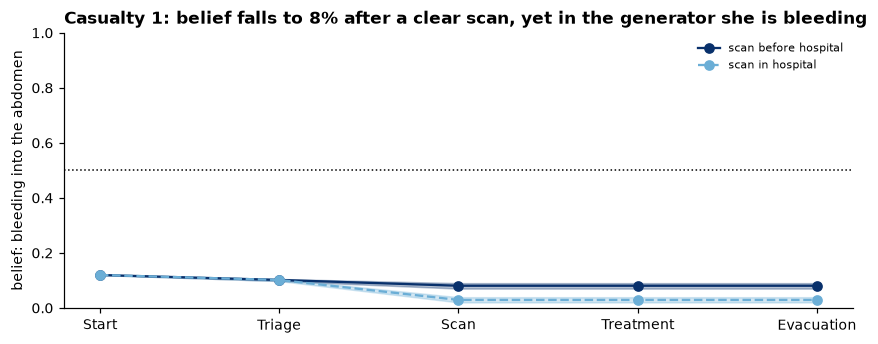

Systolic pressure 108 mm Hg (above 90). Scan before hospital: no free fluid seen. Time to pre-hospital care 40 minutes, so the tranexamic acid band is up to 1 hour; belief times relative reduction is 0.03 (0.02 to 0.04), a mechanism figure.


,Belief,95% interval,Above one half
Step,,,
Start,12%,12% to 12%,0%
Triage,10%,10% to 11%,0%
Scan,8%,7% to 9%,0%
Treatment,8%,7% to 9%,0%
Evacuation,8%,7% to 9%,0%


In [11]:
# The control: change these and run the cell again. The app's page 1 draws the same band.
PATIENT_TYPE, CASUALTY, PRIOR = "haemorrhage", 1, None     # PRIOR None means the prior from the mix

fig, ax = plt.subplots(figsize=(8, 3.2))
walks = {}
for setting, colour, style in (("pre_hospital", MID, "-"), ("in_hospital", PALE, "--")):
    w = bayes.walkthrough(PATIENT_TYPE, setting, PRIOR, CASUALTY)
    walks[setting] = w
    band = pd.DataFrame(w.band())
    ax.fill_between(band["order"], band["lo"], band["hi"], color=colour, alpha=0.3, step=None)
    ax.plot(band["order"], band["mean"], style, color=colour, marker="o", label=f"scan {bayes.SETTING_NAMES[setting]}")
ax.axhline(0.5, color="black", linestyle=":", linewidth=1)
ax.set_xticks(band["order"], band["step"])
ax.set_ylim(0, 1)
ax.set_ylabel("belief: bleeding into the abdomen")
ax.legend(fontsize=7, frameon=False)
w = walks["pre_hospital"]
truth = "is" if w.bleeding else "is not"
ax.set_title(f"Casualty {CASUALTY}: belief falls to {w.line['evacuation'].mean():.0%} after a clear scan, "
             f"yet in the generator she {truth} bleeding", loc="left")
plt.tight_layout()
plt.show()
print(walks["pre_hospital"].display()["findings"])
pd.DataFrame(walks["pre_hospital"].display()["table"]).set_index("Step")

The first haemorrhage casualty in the walk-through answers the hook in the generator's own terms. Her pressure is above 90 and her scan is clear, so the belief falls from the mix's 12% to 8% before hospital, and lower still with an in-hospital scan. She is bleeding into the abdomen. A belief of 8% means that about one casualty in twelve with her findings is bleeding; she is that one.

Is the lens right on average? On the generator that made the data, each casualty's belief can be set beside the truth. Group the casualties by their belief and compare it with the share actually bleeding.

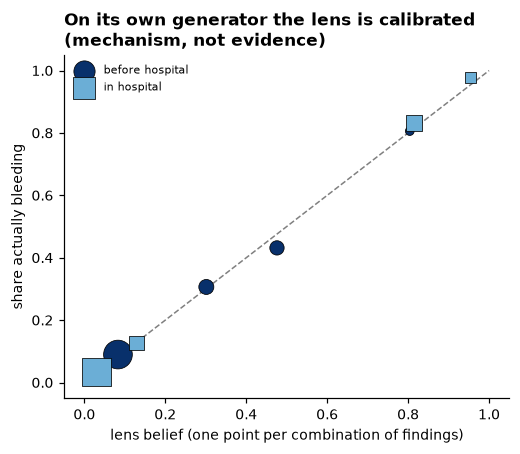

In [12]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
for setting, colour, marker in (("pre_hospital", MID, "o"), ("in_hospital", PALE, "s")):
    obs, truth = generator.sample(bayes.EVAL_N, bayes.EVAL_SEED, setting=setting, return_truth=True)
    keep = (obs["stream"] == "battle").to_numpy()
    obs, truth = obs[keep], truth[keep]
    belief_mean = bayes.beliefs(obs.reset_index(drop=True), bayes.prior_from_mix())
    table = pd.DataFrame({"belief": belief_mean, "bleeding": truth["free_fluid"].to_numpy()}).groupby("belief")
    summary = table["bleeding"].agg(["mean", "size"]).reset_index()
    ax.scatter(summary["belief"], summary["mean"], s=np.sqrt(summary["size"]) * 4, color=colour, marker=marker,
               edgecolor="black", linewidth=0.5, label=bayes.SETTING_NAMES[setting], zorder=3)
ax.plot([0, 1], [0, 1], color="grey", linewidth=1, linestyle="--")
ax.set_xlabel("lens belief (one point per combination of findings)")
ax.set_ylabel("share actually bleeding")
ax.legend(fontsize=7, frameon=False)
ax.set_title("On its own generator the lens is calibrated\n(mechanism, not evidence)", loc="left")
plt.tight_layout()
plt.show()

## Treatment: a belief about an effect

The question a clinician asks of a trial is how likely it is that the treatment works. A P value cannot answer that; it says how surprising the data would be if the treatment did nothing. PROPPR, a trial of transfusion ratios, reported P=.12 at 24 hours (E-72). A Bayesian reanalysis of the same trial gave a 93% probability that the balanced ratio was better (E-73). That is not proof. It is conditional on the model and on the prior, and the abstract of the reanalysis does not state the prior.

The treatment case here asks the same kind of question of tranexamic acid in head injury. CRASH-3 found a risk ratio for head injury-related death of 0.94 (0.86 to 1.02) in those treated within 3 hours, an interval that includes no effect (E-27). In patients with mild to moderate injury it was 0.78 (0.64 to 0.95) (E-28). CRASH-2 found a risk ratio for death from any cause of 0.91 (0.85 to 0.97) (E-20).

A published reanalysis of a prehospital tranexamic acid trial used CRASH-2 as one of its priors and narrowed the interval sharply; almost all of that certainty came from the earlier trial (E-74). The same logic is applied to CRASH-3 below, beside three other priors in the style of a published four-prior table (E-108). No published Bayesian reanalysis of CRASH-3 was confirmed in the evidence check (E-33). **This analysis is a teaching reanalysis, not a published result, and it carries the mechanism label.**

Priors are not unique to Bayesian analyses; frequentist designs carry them informally. One prehospital trial of tranexamic acid in brain injury set a significance threshold of 0.1 for benefit and 0.025 for harm, so it needed less evidence to accept benefit than harm (E-79). Here the prior is written down instead.

The priors other than CRASH-2 are assumptions: minimally informative (a normal on the log risk ratio with standard deviation 10); sceptical (centred on no effect, with a 5% chance of a reduction of a fifth or more); and enthusiastic (the same spread, centred on a reduction of a fifth).

In [13]:
rows = []
for outcome, likelihood in (("primary, treated within 3 hours (E-27)", bayes.CRASH3_HEAD_INJURY_DEATH),
                            ("mild to moderate (E-28)", bayes.CRASH3_MILD_TO_MODERATE)):
    for name, prior_summary in bayes.PRIORS.items():
        post = bayes.reread_trial(likelihood, prior_summary)
        lo, hi = post.posterior.interval()
        rows.append({"CRASH-3 result": outcome, "prior": name, "risk ratio": post.posterior.relative_risk,
                     "95% interval": f"{lo:.2f} to {hi:.2f}", "P(any benefit)": post.prob_benefit(),
                     "P(reduction of a fifth or more)": post.prob_below(0.8)})
four_priors = pd.DataFrame(rows).set_index(["CRASH-3 result", "prior"])
four_priors.round(3)

risk ratio  \
CRASH-3 result                         prior                               
primary, treated within 3 hours (E-27) minimally informative       0.940   
                                       sceptical                   0.945   
                                       enthusiastic                0.926   
                                       CRASH-2                     0.921   
mild to moderate (E-28)                minimally informative       0.780   
                                       sceptical                   0.852   
                                       enthusiastic                0.787   
                                       CRASH-2                     0.896   

                                                              95% interval  \
CRASH-3 result                         prior                                 
primary, treated within 3 hours (E-27) minimally informative  0.86 to 1.02   
                                       sceptical              0.87 to 1.03   
                                       enthusiastic           0.85 to 1.00   
                                       CRASH-2                0.87 to 0.97   
mild to moderate (E-28)                minimally informative  0.64 to 0.95   
                                       sceptical              0.73 to 1.00   
                                       enthusiastic           0.67 to 0.92   
                                       CRASH-2                0.84 to 0.95   

                                                              P(any benefit)  \
CRASH-3 result                         prior                                   
primary, treated within 3 hours (E-27) minimally informative           0.922   
                                       sceptical                       0.912   
                                       enthusiastic                    0.968   
                                       CRASH-2                         0.999   
mild to moderate (E-28)                minimally informative           0.993   
                                       sceptical                       0.976   
                                       enthusiastic                    0.998   
                                       CRASH-2                         1.000   

                                                              P(reduction of a fifth or more)  
CRASH-3 result                         prior                                                   
primary, treated within 3 hours (E-27) minimally informative                            0.000  
                                       sceptical                                        0.000  
                                       enthusiastic                                     0.000  
                                       CRASH-2                                          0.000  
mild to moderate (E-28)                minimally informative                            0.599  
                                       sceptical                                        0.218  
                                       enthusiastic                                     0.580  
                                       CRASH-2                                          0.000

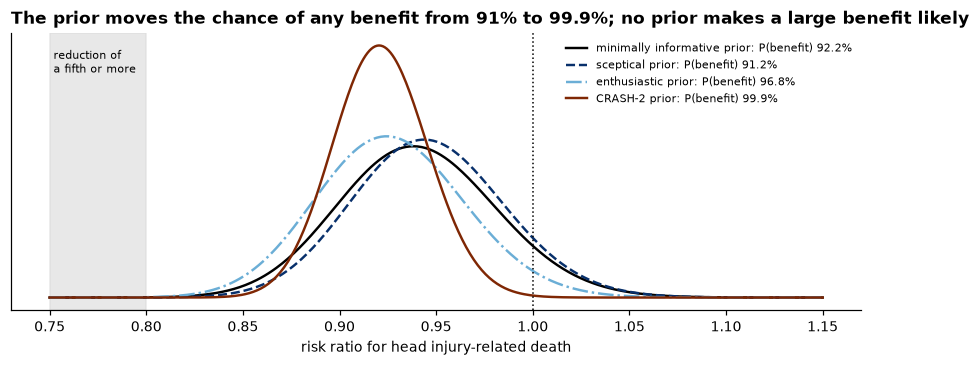

In [14]:
grid = np.linspace(0.75, 1.15, 400)
def density(summary):
    z = (np.log(grid) - summary.mean) / summary.sd
    return np.exp(-0.5 * z ** 2) / (summary.sd * grid * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(8, 3.4))
styles = {"minimally informative": ("black", "-"), "sceptical": (MID, "--"), "enthusiastic": (PALE, "-."),
          "CRASH-2": (DARK, "-")}
for name, prior_summary in bayes.PRIORS.items():
    post = bayes.reread_trial(bayes.CRASH3_HEAD_INJURY_DEATH, prior_summary)
    colour, style = styles[name]
    ax.plot(grid, density(post.posterior), style, color=colour, linewidth=1.6,
            label=f"{name} prior: P(benefit) {post.prob_benefit():.1%}")
ax.axvline(1.0, color="black", linestyle=":", linewidth=1)
ax.axvspan(0.75, 0.8, color=LIGHT, alpha=0.6)
ax.text(0.752, ax.get_ylim()[1] * 0.85, "reduction of\na fifth or more", fontsize=7)
ax.set_xlabel("risk ratio for head injury-related death")
ax.set_yticks([])
ax.legend(fontsize=7, frameon=False, loc="upper right")
probs = four_priors.loc["primary, treated within 3 hours (E-27)", "P(any benefit)"]
ax.set_title(f"The prior moves the chance of any benefit from {probs.min():.0%} to {probs.max():.1%}; "
             "no prior makes a large benefit likely", loc="left")
plt.tight_layout()
plt.show()

Three readings of the table:

- **The prior is on the table.** With the minimally informative prior the probability of any benefit is about 92%; borrowing CRASH-2 lifts it above 99%. Nothing about CRASH-3's data changed between those rows. Whether CRASH-2's patients are exchangeable with CRASH-3's is a clinical question that no formula settles.
- **What the prior cannot do.** Under every prior the chance of a reduction of a fifth or more in the primary analysis, the 9,202 patients treated within 3 hours, stays near zero.
- **The subgroup.** The mild to moderate result looks clearly positive on its own. The sceptical prior pulls it back, and the CRASH-2 prior pulls it almost to CRASH-2's own value. A subgroup is a smaller trial, and smaller trials are where the prior matters most. CRASH-2's investigators prespecified a threshold of p < 0.001 for the test of heterogeneity (E-20).

### A second trial, from the UK

RePHILL randomised patients in four English prehospital critical care services to red cells with lyophilised plasma, or to saline (E-77). It is a trial of blood products, not tranexamic acid, and its composite outcome of death or failure to clear lactate showed no difference: 64.3% against 64.8%. Another outcome, death within 3 hours, was 16% against 22%, a relative risk of 0.75 (0.50 to 1.13), an interval that includes no effect.

Re-read that one outcome with a prior. The probabilities below are **calculated here from the published interval; the trial did not report them.** They describe one outcome of the trial, and they carry the mechanism label.

In [15]:
rows = []
for name in ("minimally informative", "sceptical"):
    post = bayes.reread_trial(bayes.REPHILL_DEATH_3H, bayes.PRIORS[name])
    lo, hi = post.posterior.interval()
    rows.append({"prior": name, "risk ratio": post.posterior.relative_risk, "95% interval": f"{lo:.2f} to {hi:.2f}",
                 "P(any benefit), calculated here": post.prob_benefit()})
pd.DataFrame(rows).set_index("prior").round(3)

,risk ratio,95% interval,"P(any benefit), calculated here"
prior,,,
minimally informative,0.750,0.50 to 1.13,0.917
sceptical,0.918,0.73 to 1.15,0.775


With a flat prior the interval corresponds to about a 92% probability that early deaths were fewer with blood. That is the same order as the PROPPR reanalysis, from an interval that includes no effect. Neither number is wrong. They answer different questions, and the Bayesian one depends on a prior that has to be defended: here, that nothing was known before the trial. A sceptical prior lowers the figure.

The same function runs on a trial file. CRASH-3's patient-level data need registration, and its terms of use (open item O-2) have not been read, so the file is never in this repository. The cell below runs on the synthetic fixture, whose rows are random and mean nothing clinically, and on a real file only if a local path is supplied.

In [16]:
fixture = bayes.reread_trial(bayes.summary_from_file(bayes.FIXTURE_CRASH3), bayes.PRIORS["CRASH-2"])
lo, hi = fixture.likelihood.interval()
print(f"fixture (synthetic, mechanism): risk ratio {fixture.likelihood.relative_risk:.2f} ({lo:.2f} to {hi:.2f}); "
      f"with the CRASH-2 prior, P(any benefit) {fixture.prob_benefit():.1%}")

real_path = os.environ.get("INFERENCE_LABS_CRASH3")     # a local path outside the repository, once O-2 is closed
if real_path:
    real = bayes.reread_trial(bayes.summary_from_file(real_path), bayes.PRIORS["CRASH-2"])
    print(f"real file (evidence): P(any benefit) {real.prob_benefit():.1%}")
else:
    print("No local path supplied; the real-data cell did not run.")

fixture (synthetic, mechanism): risk ratio 0.80 (0.41 to 1.54); with the CRASH-2 prior, P(any benefit) 99.8%
No local path supplied; the real-data cell did not run.


### Carrying the belief into the benefit

The belief from the diagnosis case is used, not changed, at the treatment step. In CRASH-2, within an hour of injury, tranexamic acid reduced death from bleeding with a relative risk of 0.68 (0.57 to 0.82) (E-22). CRASH-2 is civilian, so using its figures for a military casualty is an assumption. Treat that as a random variable too (a log-normal fitted to the interval, an assumption) and multiply one minus it by the belief after a positive pre-hospital scan.

In [17]:
rr = bayes.relative_risk_draws("up to 1 hour")
positive_pre = bayes.belief_after_scan(0.20, "pre_hospital")
weighted = positive_pre * (1 - rr)
lo, hi = weighted.interval()
print(f"point arithmetic:  {positive_pre.mean():.2f} x {1 - 0.68:.2f} = {positive_pre.mean() * (1 - 0.68):.2f}")
print(f"random variable:   {weighted.mean():.2f}, range {lo:.2f} to {hi:.2f}")

point arithmetic:  0.65 x 0.32 = 0.21
random variable:   0.21, range 0.11 to 0.31


The middle is the same; the point arithmetic hides that belief times relative reduction spans nearly threefold. This step applies a population average to one casualty's belief, so it is a modelling step and carries the mechanism label. It is a diagnosis result put to use, not a treatment result.

## The failure: a prior from the wrong population

The characteristic failure of a Bayesian lens is not in the arithmetic. It is in what is fed to it. The commonest version here is to take the scan's accuracy from the in-hospital studies and use it before hospital. Nothing in the arithmetic objects.

A quieter borrowing sits inside the pre-hospital figure itself. A third of that service's abdominal scans were recorded as indeterminate, and the paper does not make clear how they enter its two-by-two table (E-16). The 25% therefore describes scans that were called, not scans attempted. Used for every scan a medic attempts, it describes a different test from the one that was measured.

The generator draws no indeterminate scans, so it cannot show that borrowing. It can show the first, in-hospital accuracy used before hospital, because it knows the truth. Among its haemorrhage casualties, the share bleeding into the abdomen is close to the one in five assumed above. Take those with a positive scan before hospital and count how many are bleeding.

In [18]:
obs, truth = generator.sample(100_000, bayes.SEED, setting="pre_hospital", return_truth=True)
haem = (truth["patient_type"] == "haemorrhage").to_numpy()
positive = obs["scan_free_fluid"].fillna(False).to_numpy(bool)
bleeding_ab = truth["free_fluid"].to_numpy(bool)
share_prior = bleeding_ab[haem].mean()
observed = bleeding_ab[haem & positive].mean()

right = bayes.belief_after_scan(share_prior, "pre_hospital")
wrong = bayes.belief_after_scan(share_prior, "in_hospital")    # in-hospital accuracy applied before hospital
print(f"haemorrhage casualties bleeding into the abdomen: {share_prior:.1%}")
print(f"of those with a positive scan before hospital, bleeding: {observed:.1%} (n = {(haem & positive).sum():,})")
print(f"belief with pre-hospital accuracy: {right.mean():.1%}   with borrowed in-hospital accuracy: {wrong.mean():.1%}")

haemorrhage casualties bleeding into the abdomen: 21.2%
of those with a positive scan before hospital, bleeding: 64.9% (n = 1,501)
belief with pre-hospital accuracy: 67.1%   with borrowed in-hospital accuracy: 90.9%


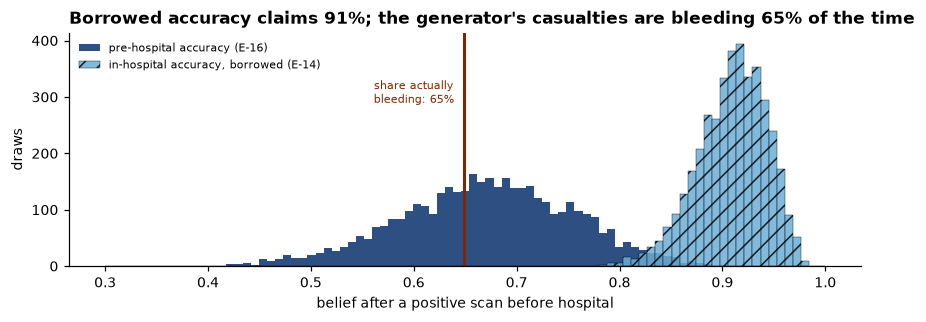

In [19]:
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(0.3, 1, 90)
ax.hist(right.draws, bins=bins, color=MID, alpha=0.85, label="pre-hospital accuracy (E-16)")
ax.hist(wrong.draws, bins=bins, color=PALE, alpha=0.85, hatch="//", edgecolor="black", linewidth=0.3,
        label="in-hospital accuracy, borrowed (E-14)")
ax.axvline(observed, color=DARK, linewidth=2)
ax.text(observed - 0.01, ax.get_ylim()[1] * 0.7, f"share actually\nbleeding: {observed:.0%}", ha="right", fontsize=7, color=DARK)
ax.set_xlabel("belief after a positive scan before hospital")
ax.set_ylabel("draws")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title(f"Borrowed accuracy claims {wrong.mean():.0%}; the generator's casualties are bleeding {observed:.0%} of the time",
             loc="left")
plt.tight_layout()
plt.show()

### Updating twice on the same blood loss

The second failure is counting one piece of evidence twice. Each update assumes the new finding is independent of the earlier ones, given the condition. Two readings of the same thing are not.

In this generator the scan and the systolic pressure are drawn independently given abdominal bleeding, so combining them is sound here: the arithmetic and the count agree. The failure appears where two readings share a cause. Two cases, both counted on the generator's battle casualties before hospital:

- **One scan, reported twice.** The positive scan is recorded at pre-hospital care and then entered again from the handover note as if it were a second finding.
- **Two signs of one hidden state.** A heart rate over 100 and being unable to walk. In the generator both depend on the casualty's hidden state, but each is drawn separately from that state, so given abdominal bleeding they are close to independent.

In [20]:
battle = (obs["stream"] == "battle").to_numpy()
prior_mix = bleeding_ab[battle].mean()
odds = prior_mix / (1 - prior_mix)

def lr(reading):
    return reading[battle & bleeding_ab].mean() / reading[battle & ~bleeding_ab].mean()

def prob(o):
    return o / (1 + o)

fast = (obs["heart_rate"] > 100).to_numpy()
cannot_walk = (~obs["walking"]).to_numpy()
low_pressure = (obs["sbp"] <= bayes.TRIAGE_SBP_AT_OR_BELOW).to_numpy()
cases = {
    "scan and pressure\n(independent)": (prob(odds * lr(positive) * lr(low_pressure)), bleeding_ab[battle & positive & low_pressure].mean()),
    "one scan, counted twice": (prob(odds * lr(positive) ** 2), bleeding_ab[battle & positive].mean()),
    "fast pulse and\ncannot walk": (prob(odds * lr(fast) * lr(cannot_walk)), bleeding_ab[battle & fast & cannot_walk].mean()),
}
pd.DataFrame(cases, index=["belief, multiplying as if independent", "share actually bleeding"]).T.round(3)

,"belief, multiplying as if independent",share actually bleeding
scan and pressure\n(independent),0.778,0.788
"one scan, counted twice",0.860,0.486
fast pulse and\ncannot walk,0.195,0.189


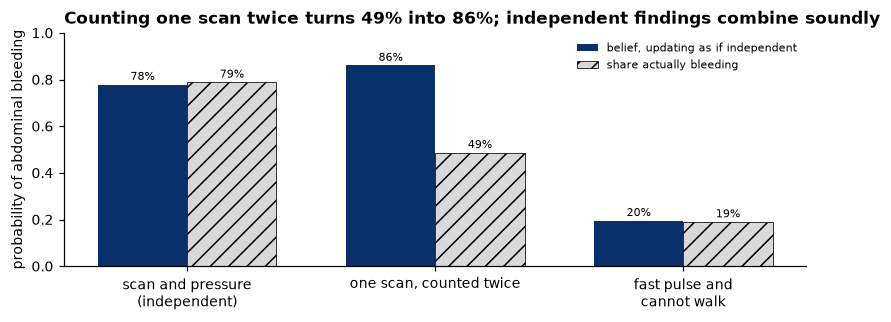

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 3))
x = np.arange(len(cases))
naive = [v[0] for v in cases.values()]
actual = [v[1] for v in cases.values()]
ax.bar(x - 0.18, naive, 0.36, color=MID, label="belief, updating as if independent")
ax.bar(x + 0.18, actual, 0.36, color=LIGHT, edgecolor="black", hatch="//", linewidth=0.5, label="share actually bleeding")
for i, (n, a) in enumerate(zip(naive, actual)):
    ax.text(i - 0.18, n + 0.02, f"{n:.0%}", ha="center", fontsize=7)
    ax.text(i + 0.18, a + 0.02, f"{a:.0%}", ha="center", fontsize=7)
ax.set_xticks(x, list(cases))
ax.set_ylim(0, 1)
ax.set_ylabel("probability of abdominal bleeding")
ax.legend(fontsize=7, frameon=False, loc="upper right")
ax.set_title(f"Counting one scan twice turns {actual[1]:.0%} into {naive[1]:.0%}; independent findings combine soundly",
             loc="left")
plt.tight_layout()
plt.show()

### Breaking the pairing

The third failure is the one the random variable makes possible. Sensitivity and the miss rate are two views of one quantity, so draw by draw they add to exactly one. Shuffle the draws of one of them, as happens if the two are sampled separately or sorted, and add again.

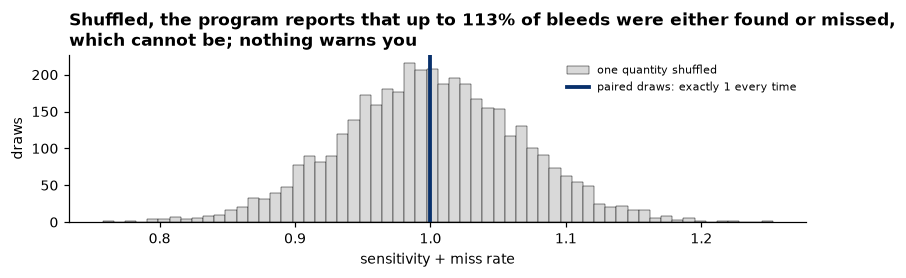

paired: every draw equals 1: True;  shuffled 95% range: 0.87 to 1.13


In [22]:
sens, _ = bayes.scan_accuracy("pre_hospital")
miss = 1 - sens
paired = sens + miss
shuffled = sens + RV(np.random.default_rng(0).permutation(miss.draws))
lo, hi = shuffled.interval()

fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.hist(shuffled.draws, bins=60, color=LIGHT, edgecolor="black", linewidth=0.3, label="one quantity shuffled")
ax.axvline(1.0, color=MID, linewidth=2.5, label="paired draws: exactly 1 every time")
ax.set_xlabel("sensitivity + miss rate")
ax.set_ylabel("draws")
ax.legend(fontsize=7, frameon=False)
ax.set_title(f"Shuffled, the program reports that up to {hi:.0%} of bleeds were either found or missed,\n"
             "which cannot be; nothing warns you", loc="left")
plt.tight_layout()
plt.show()
print(f"paired: every draw equals 1: {np.allclose(paired.draws, 1)};  shuffled 95% range: {lo:.2f} to {hi:.2f}")

A quieter version is summarising too early: take the mean at the scan step, pass 65% on, and every later step inherits a certainty the scan never had. Summaries belong at the end of the pathway.

## Scorecard

Every row is measured on synthetic data, so every row carries the **mechanism** label: the generator's casualties for the diagnosis case and the synthetic fixture for the treatment case. A row would carry the **evidence** label only if it were computed from a real trial file read from a local path outside the repository.

The baseline is the MPTT-24, the rule a medic would use (D-9), under its default reading of the published flowchart and run on the same synthetic casualties. It gives no probability, so its Priority 1 is counted as a flag for abdominal bleeding: its Brier score is then the share misclassified, and its calibration row is the share flagged minus the share bleeding. The rule was written to find casualties who need a life-saving intervention, not abdominal bleeding, so this asks it a question it was not built for; its figures are a mechanism and say nothing about how it performs on real casualties. It does not use the scan, so its figures are the same in both settings. The generator's assumed physiology is tuned so that, on the injured, the rule lands near its published accuracy, which was measured on first hospital observations, so the rows marked before hospital do not describe the rule at the point of injury. The treatment row has no baseline figure, because the rule states no probability that a treatment works; the table says so in words. Fit is native for diagnosis and weak for treatment: the lens does not choose a treatment; it hands its belief to the step that does.

In [23]:
card = pd.DataFrame([vars(row) for row in bayes.LENS.scorecard()])
card["baseline"] = card["baseline"].astype(object).where(card["baseline"].notna(),
                                                         "not applicable: the rule gives no probability")
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, belief above one half, before hos...",0.048,0.577,mechanism,native,generator
1,diagnosis,"specificity, belief above one half, before hos...",0.998,0.578,mechanism,native,generator
2,diagnosis,"Brier score, before hospital",0.100,0.422,mechanism,native,generator
3,diagnosis,"mean belief minus observed share, before hospital",-0.004,0.314,mechanism,native,generator
4,diagnosis,"sensitivity, belief above one half, in hospital",0.729,0.577,mechanism,native,generator
5,diagnosis,"specificity, belief above one half, in hospital",0.983,0.578,mechanism,native,generator
6,diagnosis,"Brier score, in hospital",0.046,0.422,mechanism,native,generator
7,diagnosis,"mean belief minus observed share, in hospital",-0.005,0.314,mechanism,native,generator
8,treatment,probability tranexamic acid reduces head injur...,0.998,not applicable: the rule gives no probability,mechanism,weak,fixture:crash3.csv


Two rows carry the lesson. Before hospital, a belief above one half catches only a small share of the casualties bleeding into the abdomen, because a positive scan there rarely carries the belief past the line on its own. In hospital the same lens catches most of them. On the generator the lens is calibrated in both settings, which confirms its arithmetic, not its truth.

Against the baseline: before hospital the MPTT-24's Priority 1 flags more of the casualties bleeding into the abdomen than the lens does, at the price of flagging many more who are not; in hospital the lens does better on both counts. The comparison is made on the generator, with the rule asked a question it was not written for.

**Teach back.** In one sentence, why does a clear scan before hospital barely move the belief, when a positive one moves it a long way?

## The brain analogy, and where it breaks

**What it resembles.** Predictive coding is a model of visual cortex in which feedback connections carry predictions down and feedforward connections carry up the error between the prediction and the input (E-55). The shape is the same as a belief update: a prior expectation, an incoming finding, and a correction whose size depends on how far the finding departs from what was expected.

**Where it breaks.** Predictive coding is a model of how one part of the visual system may work. It is not evidence that the brain computes posterior probabilities, still less that clinicians do. Nothing in this notebook says how people reason; it shows what the arithmetic of belief does with the evidence it is given, and what goes wrong when that evidence comes from the wrong population or is counted twice.